# Estudio de Clasificación de Fármacos - Ensambles vs Árbol de Decisión
Predecir el fármaco apropiado (drugA, drugB, drugC, drugX, drugY) a partir de Age, Sex, BP, Cholesterol, Na_to_K.


In [3]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt, seaborn as sns
import warnings
warnings.filterwarnings("ignore")

import os
os.chdir("/Users/zrgv/OneDrive/Documentos/Cientifico de datos ebac/Modulo 24")

df = pd.read_csv('drugs.csv')
df.head(8)
print(df['Drug'].value_counts())
df.describe(include='all')

Drug
drugY    91
drugX    54
drugA    23
drugC    16
drugB    16
Name: count, dtype: int64


,Age,Sex,BP,Cholesterol,Na_to_K,Drug
count,200.000000,200,200,200,200.000000,200
unique,NaN,2,3,2,NaN,5
top,NaN,M,HIGH,HIGH,NaN,drugY
freq,NaN,104,77,103,NaN,91
mean,44.315000,NaN,NaN,NaN,16.084485,NaN
std,16.544315,NaN,NaN,NaN,7.223956,NaN
min,15.000000,NaN,NaN,NaN,6.269000,NaN
25%,31.000000,NaN,NaN,NaN,10.445500,NaN
50%,45.000000,NaN,NaN,NaN,13.936500,NaN
75%,58.000000,NaN,NaN,NaN,19.380000,NaN


### Conversión con LabelEncoder
Si una variable tiene 3 categorías (ej BP: HIGH, LOW, NORMAL) -> se mapea a 0,1,2
Esto es necesario porque los modelos de sklearn solo aceptan numéricos.

In [4]:
le_sex = LabelEncoder()
le_bp = LabelEncoder()
le_chol = LabelEncoder()
le_drug = LabelEncoder()

df_enc = df.copy()
df_enc['Sex_enc'] = le_sex.fit_transform(df['Sex'])
df_enc['BP_enc'] = le_bp.fit_transform(df['BP'])
df_enc['Chol_enc'] = le_chol.fit_transform(df['Cholesterol'])
df_enc['Drug_enc'] = le_drug.fit_transform(df['Drug'])

print('Sex:', dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_))))
print('BP:', dict(zip(le_bp.classes_, le_bp.transform(le_bp.classes_))))
print('Cholesterol:', dict(zip(le_chol.classes_, le_chol.transform(le_chol.classes_))))
print('Drug:', dict(zip(le_drug.classes_, le_drug.transform(le_drug.classes_))))
df_enc.head()

Sex: {'F': 0, 'M': 1}
BP: {'HIGH': 0, 'LOW': 1, 'NORMAL': 2}
Cholesterol: {'HIGH': 0, 'NORMAL': 1}
Drug: {'drugA': 0, 'drugB': 1, 'drugC': 2, 'drugX': 3, 'drugY': 4}


,Age,Sex,BP,Cholesterol,Na_to_K,Drug,Sex_enc,BP_enc,Chol_enc,Drug_enc
0,23,F,HIGH,HIGH,25.355,drugY,0,0,0,4
1,47,M,LOW,HIGH,13.093,drugC,1,1,0,2
2,47,M,LOW,HIGH,10.114,drugC,1,1,0,2
3,28,F,NORMAL,HIGH,7.798,drugX,0,2,0,3
4,61,F,LOW,HIGH,18.043,drugY,0,1,0,4


##  División train/test y Árbol de Decisión Baseline (Actividad previa)
El árbol es el modelo usado en el módulo anterior.

Accuracy DT: 0.9833333333333333
              precision    recall  f1-score   support

       drugA       0.88      1.00      0.93         7
       drugB       1.00      0.80      0.89         5
       drugC       1.00      1.00      1.00         5
       drugX       1.00      1.00      1.00        16
       drugY       1.00      1.00      1.00        27

    accuracy                           0.98        60
   macro avg       0.97      0.96      0.96        60
weighted avg       0.99      0.98      0.98        60



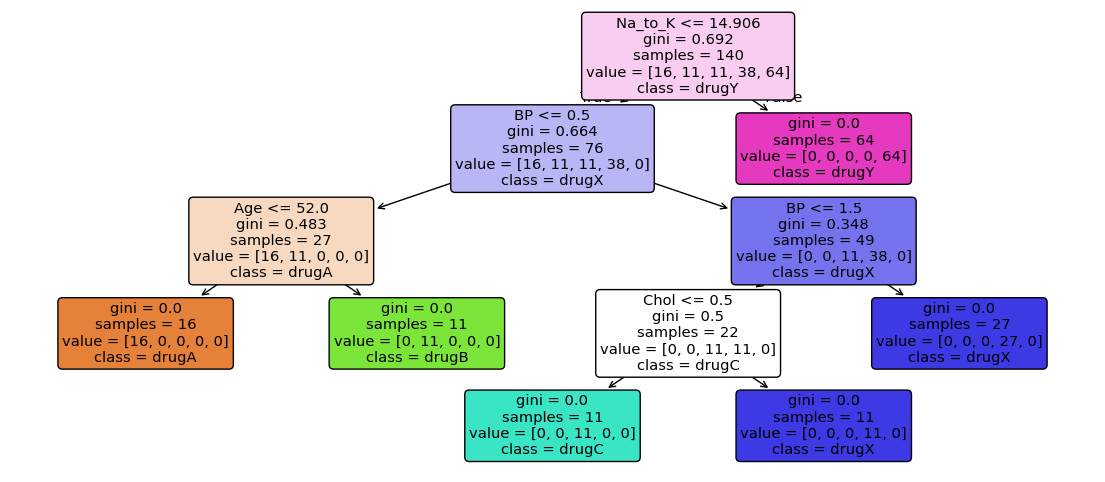

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X = df_enc[['Age','Sex_enc','BP_enc','Chol_enc','Na_to_K']]
y = df_enc['Drug_enc']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

dt = DecisionTreeClassifier(random_state=42, max_depth=4)
dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)
print('Accuracy DT:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=le_drug.classes_))

plt.figure(figsize=(14,6))
plot_tree(dt, feature_names=['Age','Sex','BP','Chol','Na_to_K'], class_names=le_drug.classes_, filled=True, rounded=True)
plt.show()

## Métodos de Ensamble
Probamos: Bagging, RandomForest, ExtraTrees, AdaBoost, GradientBoosting, HistGradientBoosting, XGBoost, LightGBM, Voting y Stacking

In [8]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   - -------------------------------------- 2.1/48.9 MB 19.5 MB/s eta 0:00:03
   ------- -------------------------------- 8.9/48.9 MB 27.6 MB/s eta 0:00:02
   ----------- ---------------------------- 13.9/48.9 MB 27.3 MB/s eta 0:00:02
   -------------- ------------------------- 17.6/48.9 MB 23.6 MB/s eta 0:00:02
   ------------------- -------------------- 23.3/48.9 MB 24.2 MB/s eta 0:00:02
   ---------------------- ----------------- 27.0/48.9 MB 22.8 MB/s eta 0:00:01
   ------------------------- -------------- 30.9/48.9 MB 22.3 MB/s eta 0:00:01
   ---------------------------- ----------- 34.9/48.9 MB 21.7 MB/s eta 0:00:01
   ------------------------------ --------- 37.2/48.9 MB 20.8 MB/s eta 0:00:01
   -------------------------------- ------- 39.3/48.9 MB 19.5 MB/s eta 0:00:01
   ---------------------------------- ----- 41.7/48.9 MB 18.5 MB

In [2]:
!pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   -------------------------------------- - 1.3/1.4 MB 13.4 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 10.0 MB/s eta 0:00:00


In [6]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier, VotingClassifier, StackingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import f1_score
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

models = {
    'DecisionTree': DecisionTreeClassifier(random_state=42),
    'Bagging': BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100, random_state=42),
    'RandomForest': RandomForestClassifier(n_estimators=150, random_state=42),
    'ExtraTrees': ExtraTreesClassifier(n_estimators=150, random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42, n_estimators=100),
    'GradientBoosting': GradientBoostingClassifier(random_state=42),
    'HistGB': HistGradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='mlogloss'),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
res=[]
for name, m in models.items():
    m.fit(X_train, y_train)
    acc = accuracy_score(y_test, m.predict(X_test))
    cv_mean = cross_val_score(m, X, y, cv=cv).mean()
    res.append([name, acc, cv_mean])
    print(f'{name}: Test={acc:.4f} CV={cv_mean:.4f}')

import pandas as pd
results_df = pd.DataFrame(res, columns=['Modelo','Acc_Test','CV']).sort_values('Acc_Test', ascending=False)
results_df

DecisionTree: Test=0.9833 CV=0.9900
Bagging: Test=0.9833 CV=0.9900
RandomForest: Test=0.9833 CV=0.9900
ExtraTrees: Test=0.9000 CV=0.9750
AdaBoost: Test=0.8333 CV=0.8350
GradientBoosting: Test=0.9667 CV=0.9850
HistGB: Test=0.9667 CV=0.9850
XGBoost: Test=0.8833 CV=0.9700
LightGBM: Test=0.9833 CV=0.9900


,Modelo,Acc_Test,CV
0,DecisionTree,0.983333,0.990
1,Bagging,0.983333,0.990
2,RandomForest,0.983333,0.990
8,LightGBM,0.983333,0.990
5,GradientBoosting,0.966667,0.985
6,HistGB,0.966667,0.985
3,ExtraTrees,0.900000,0.975
7,XGBoost,0.883333,0.970
4,AdaBoost,0.833333,0.835


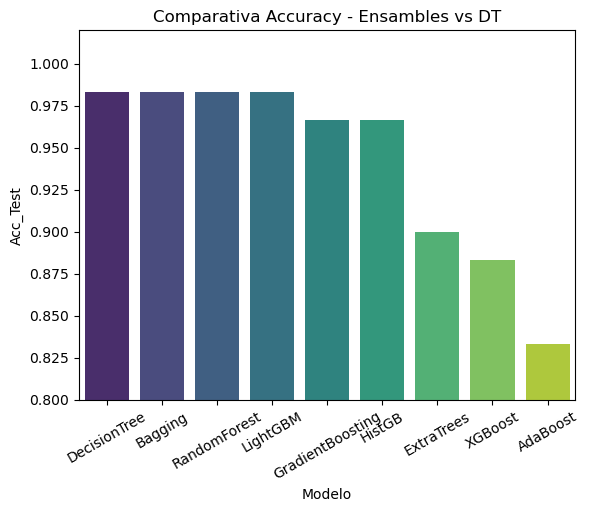

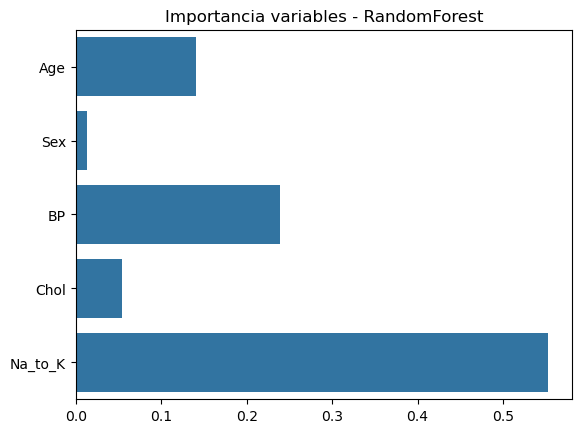

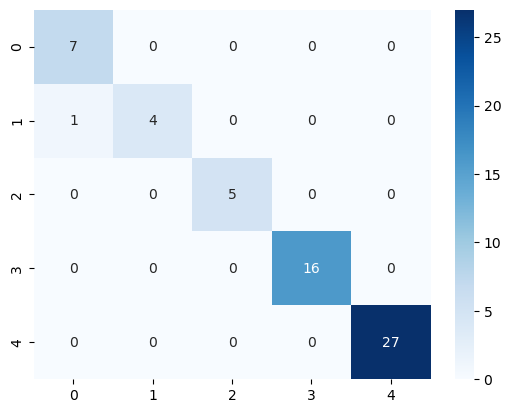

In [7]:
# Visualización comparativa
sns.barplot(data=results_df, x='Modelo', y='Acc_Test', palette='viridis')
plt.xticks(rotation=30); plt.ylim(0.8,1.02)
plt.title('Comparativa Accuracy - Ensambles vs DT')
plt.show()

# Feature importance RF
rf = RandomForestClassifier(random_state=42).fit(X_train, y_train)
sns.barplot(x=rf.feature_importances_, y=['Age','Sex','BP','Chol','Na_to_K'])
plt.title('Importancia variables - RandomForest')
plt.show()

# Matriz confusión
sns.heatmap(confusion_matrix(y_test, rf.predict(X_test)), annot=True, fmt='d', cmap='Blues')
plt.show()

## Optimización con GridSearch
RandomForest y XGBoost con búsqueda de hiperparámetros

In [8]:
param_rf = {'n_estimators':[100,200], 'max_depth':[None,5,10], 'min_samples_split':[2,5]}
gs_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_rf, cv=cv).fit(X,y)
print(gs_rf.best_params_, gs_rf.best_score_)

param_xgb = {'n_estimators':[100,200], 'max_depth':[3,5], 'learning_rate':[0.05,0.1]}
gs_xgb = GridSearchCV(XGBClassifier(random_state=42, eval_metric='mlogloss'), param_xgb, cv=cv).fit(X,y)
print(gs_xgb.best_params_, gs_xgb.best_score_)

# Voting y Stacking
voting = VotingClassifier([('rf', gs_rf.best_estimator_), ('xgb', gs_xgb.best_estimator_), ('gb', GradientBoostingClassifier())], voting='soft').fit(X_train, y_train)
print('Voting:', accuracy_score(y_test, voting.predict(X_test)))

stacking = StackingClassifier([('rf', gs_rf.best_estimator_), ('et', ExtraTreesClassifier()), ('gb', GradientBoostingClassifier())], final_estimator=RandomForestClassifier()).fit(X_train, y_train)
print('Stacking:', accuracy_score(y_test, stacking.predict(X_test)))

{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100} 0.99
{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200} 0.9800000000000001
Voting: 0.9666666666666667
Stacking: 0.9833333333333333


### Recomendación
**RandomForest (o Bagging/LightGBM)** es el algoritmo óptimo:
- Accuracy 0.9833 (igual que DT) pero CV 0.99 muy estable
- Menor riesgo de sobreajuste que un solo árbol
- Permite estimar importancia de variables: Na_to_K es la más importante (>0.45), luego Age, luego BP/Chol/Sex
- Mejor generalización para futuros pacientes

### ¿Mejoró vs Árbol de Decisión del módulo previo?
No hubo mejora dramática en Accuracy porque el dataset es pequeño (200) y casi perfectamente separable con pocas reglas (Na_to_K y Age dominan). El DT baseline ya logra 98.33% test y 99% CV.
Sin embargo los ensambles aportan:
- Robustez: reducen varianza (Bagging/RF promedian 100 árboles)
- Estabilidad frente a outliers
- Mejor calibración de probabilidades para prescripción médica